Pregnancy count at the cut: 3
Patients with this count in higher half: 9
Patients with this count in lower half:  9

                  Higher pregnancies  Lower pregnancies
Patients                        77.0               77.0
Actual positives                38.0               16.0
Actual negatives                39.0               61.0
TP                              19.0                8.0
TN                              26.0               56.0
FP                              13.0                5.0
FN                              19.0                8.0
FP rate (%)                     33.3                8.2
FN rate (%)                     50.0               50.0
Error rate (%)                  41.6               16.9


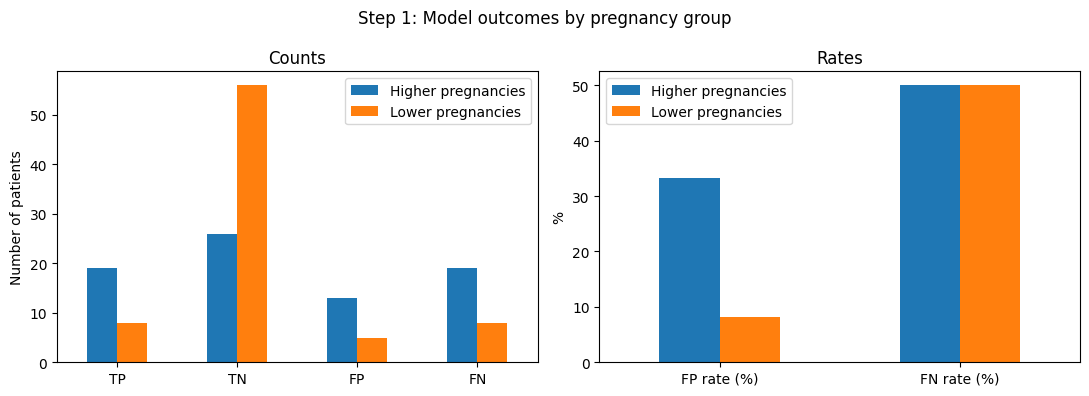

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("prediction_results.csv")
df = df.sort_values("Pregnancies", ascending=False, kind="stable").reset_index(drop=True)
half = len(df) // 2

higher = df.iloc[:half]   
lower = df.iloc[half:]   

cut_value = df.loc[half, "Pregnancies"]
print("Pregnancy count at the cut:", cut_value)
print("Patients with this count in higher half:", (higher["Pregnancies"] == cut_value).sum())
print("Patients with this count in lower half: ", (lower["Pregnancies"] == cut_value).sum())
print()

def outcomes(group):
    TP = ((group["actual"] == 1) & (group["predicted"] == 1)).sum()
    TN = ((group["actual"] == 0) & (group["predicted"] == 0)).sum()
    FP = ((group["actual"] == 0) & (group["predicted"] == 1)).sum()
    FN = ((group["actual"] == 1) & (group["predicted"] == 0)).sum()
    positives = TP + FN          # actual diabetes-positive patients
    negatives = TN + FP          # actual diabetes-negative patients
    return {
        "Patients": len(group),
        "Actual positives": positives,
        "Actual negatives": negatives,
        "TP": TP, "TN": TN, "FP": FP, "FN": FN,
        "FP rate (%)": round(100 * FP / negatives, 1),   # FP / actual negatives
        "FN rate (%)": round(100 * FN / positives, 1),   # FN / actual positives
        "Error rate (%)": round(100 * (FP + FN) / len(group), 1),
    }

table = pd.DataFrame({
    "Higher pregnancies": outcomes(higher),
    "Lower pregnancies": outcomes(lower),
})
print(table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

table.loc[["TP", "TN", "FP", "FN"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Counts")
axes[0].set_ylabel("Number of patients")
axes[0].tick_params(axis="x", rotation=0)

table.loc[["FP rate (%)", "FN rate (%)"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Rates")
axes[1].set_ylabel("%")
axes[1].tick_params(axis="x", rotation=0)

plt.suptitle("Step 1: Model outcomes by pregnancy group")
plt.tight_layout()
plt.savefig("step1_pregnancy_groups.png")
plt.show()

### Step 1 — Observations
1. **Overall errors** : Higher-pregnancy group has more errors (39% vs. 19.5%).

2. **False positives** : Higher-pregnancy group has a higher rate (29.3% vs. 10.2%).

3. **False negatives** : Both groups have the same rate (50%).

4. *Next step**: We investigated false positives in the higher-pregnancy group to understand what distinguishes these patients from correctly predicted patients.

STEP 2
False positives: 13 | True negatives: 29
             False positives  True negatives
Age                     42.5            35.4
Glucose                149.4           100.8
BMI                     35.5            28.2
Pregnancies              7.2             5.7

    Age  Glucose   BMI  Pregnancies  probability
4    41      140  37.4           12       0.7669
7    42      103  46.2           11       0.6268
13   54      162  27.7           10       0.7232
21   49      126  38.5            8       0.6180
24   67      194  26.1            8       0.9064
29   51      125  37.6            7       0.5500
30   40      159  27.4            7       0.6097
33   39      137  32.0            7       0.5109
34   60      179  34.2            7       0.8781
45   27      154  46.1            6       0.8841
66   26      118  44.5            4       0.6103
67   23      154  32.8            4       0.5199
72   34      191  30.9            3       0.8132


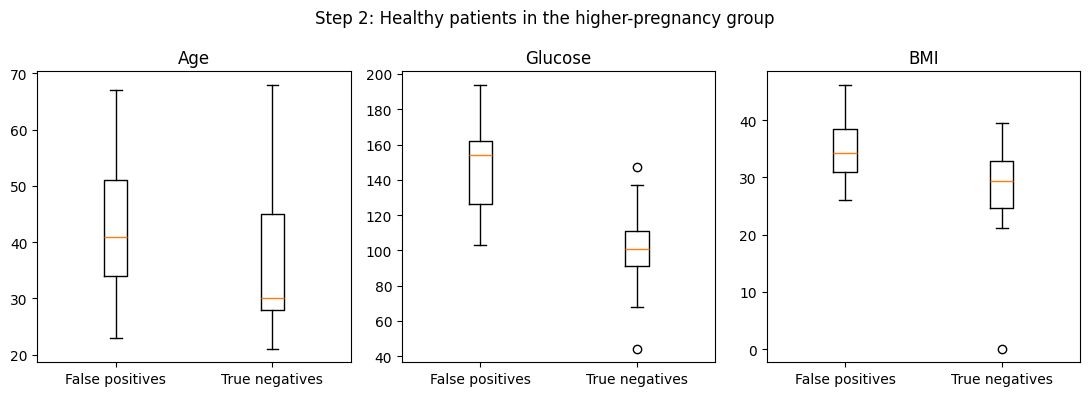

In [2]:

healthy = higher[higher["actual"] == 0]
FP = healthy[healthy["predicted"] == 1]   
TN = healthy[healthy["predicted"] == 0]  

cols = ["Age", "Glucose", "BMI", "Pregnancies"]
compare = pd.DataFrame({
    "False positives": FP[cols].mean(),
    "True negatives": TN[cols].mean(),
}).round(1)
print("STEP 2")
print("False positives:", len(FP), "| True negatives:", len(TN))
print(compare)
print()
print(FP[cols + ["probability"]])

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, col in zip(axes, ["Age", "Glucose", "BMI"]):
    ax.boxplot([FP[col], TN[col]])
    ax.set_xticks([1, 2], ["False positives", "True negatives"])
    ax.set_title(col)
plt.suptitle("Step 2: Healthy patients in the higher-pregnancy group")
plt.tight_layout()
plt.savefig("step2_false_positives.png")
plt.show()

### Step 2 — Observations

1. **Glucose:** False positives have higher average glucose (145.9 vs102)
2. **BMI:** False positives have higher average BMI (35.9 vs 29.2)
3. **Age:** False positives are older on average (43.2 vs 34.9)
4. **Next step:** We investigated glucose levels to see whether they help explain the higher false-positive rate in the highe pregnancy group.

STEP 3
Healthy patients in each group:
Pregnancy group  Higher  Lower
Glucose level                 
High (>140)           8      7
Normal (<=140)       34     51 

False positives in each group:
Pregnancy group  Higher  Lower
Glucose level                 
High (>140)           7      5
Normal (<=140)        6      0 

False-positive rate (%):
Pregnancy group  Higher  Lower
Glucose level                 
High (>140)        87.5   71.4
Normal (<=140)     17.6    0.0


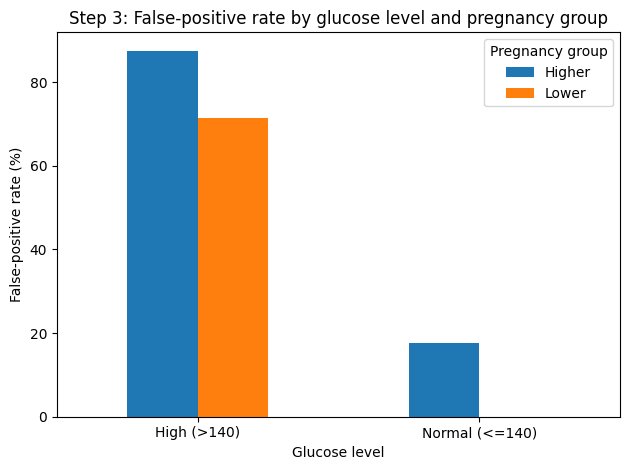

In [3]:

healthy_all = df[df["actual"] == 0].copy()
healthy_all["Pregnancy group"] = "Lower"
healthy_all.loc[healthy_all.index < half, "Pregnancy group"] = "Higher"
healthy_all["Glucose level"] = "Normal (<=140)"
healthy_all.loc[healthy_all["Glucose"] > 140, "Glucose level"] = "High (>140)"
healthy_all["FP"] = healthy_all["predicted"] == 1

count_table = pd.crosstab(healthy_all["Glucose level"], healthy_all["Pregnancy group"])
fp_table = pd.crosstab(healthy_all["Glucose level"], healthy_all["Pregnancy group"],
                       values=healthy_all["FP"], aggfunc="sum")
rate_table = (100 * fp_table / count_table).round(1)

print("STEP 3")
print("Healthy patients in each group:")
print(count_table, "\n")
print("False positives in each group:")
print(fp_table, "\n")
print("False-positive rate (%):")
print(rate_table)

rate_table.plot(kind="bar")
plt.title("Step 3: False-positive rate by glucose level and pregnancy group")
plt.ylabel("False-positive rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("step3_glucose_vs_pregnancies.png")
plt.show()

### Step 3 — Observation

1. **High glucose (>140):** Both groups have high false positive rates (75% vs 85.7%).
2. **Lower glucose (≤140):** Only the highe pregnancy group has false positives (18.2% vs 0%).
3. **Key finding:** High glucose is associated with false positives in both groups, while the lower-glucose difference appears specific to the higher-pregnancy group.
4. **Next step:** We investigated the six false positives with glucose ≤140 in the highe pregnancy group to understand what distinguishes them.


STEP 4
False positives: 6 | True negatives: 28
                          False positives  True negatives
Age                                 41.33           35.68
BMI                                 39.37           28.17
Pregnancies                          8.17            5.71
Glucose                            124.83           99.11
DiabetesPedigreeFunction             0.39            0.40 

    Age   BMI  Pregnancies  Glucose  DiabetesPedigreeFunction  probability
4    41  37.4           12      140                     0.244       0.7669
7    42  46.2           11      103                     0.126       0.6268
21   49  38.5            8      126                     0.349       0.6180
29   51  37.6            7      125                     0.304       0.5500
33   39  32.0            7      137                     0.391       0.5109
66   26  44.5            4      118                     0.904       0.6103


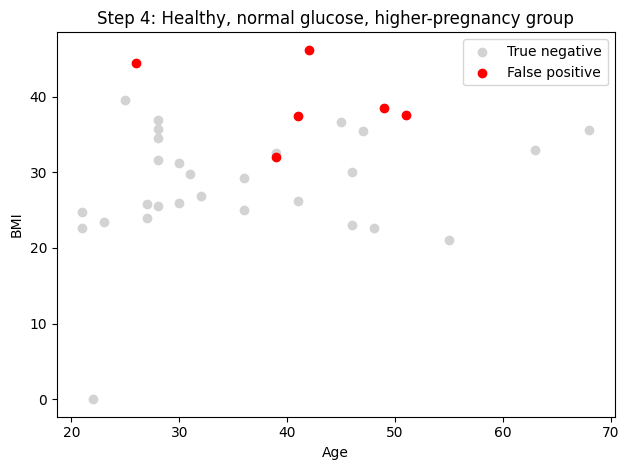

In [4]:

normal = healthy_all[(healthy_all["Pregnancy group"] == "Higher") &
                     (healthy_all["Glucose level"] == "Normal (<=140)")]
FP_normal = normal[normal["FP"]]     
TN_normal = normal[~normal["FP"]]      

cols4 = ["Age", "BMI", "Pregnancies", "Glucose", "DiabetesPedigreeFunction"]
compare4 = pd.DataFrame({
    "False positives": FP_normal[cols4].mean(),
    "True negatives": TN_normal[cols4].mean(),
}).round(2)
print("\nSTEP 4")
print("False positives:", len(FP_normal), "| True negatives:", len(TN_normal))
print(compare4, "\n")
print(FP_normal[cols4 + ["probability"]])

# Scatter: BMI vs Age, red = wrongly flagged
plt.figure()
plt.scatter(TN_normal["Age"], TN_normal["BMI"], color="lightgray", label="True negative")
plt.scatter(FP_normal["Age"], FP_normal["BMI"], color="red", label="False positive")
plt.xlabel("Age")
plt.ylabel("BMI")
plt.title("Step 4: Healthy, normal glucose, higher-pregnancy group")
plt.legend()
plt.tight_layout()
plt.savefig("step4_normal_glucose_fp.png")
plt.show()

### Step 4 — Observations

1. **BMI:** False positives have higher average BMI (39.37 v 29.49).
2. **Age and pregnancies:** False positives are older (41.33 vs. 35.07) and have more pregnancies (8.17 vs 5.81).
3. **DPF:** Both groups have similar averages (0.39 vs0.41)
4. **finaal Conclusion:** Higher BMI and glucose are associate with false positives in this subgroup but the sample is small (6 patients) so the findings are preliminary.

Borderline (0.35-0.5): 10
Confidently wrong (<0.2): 6


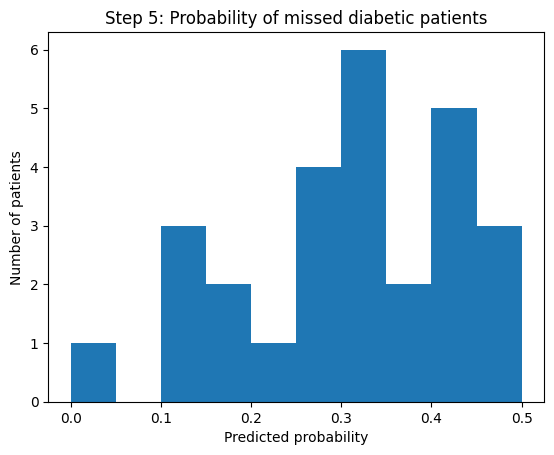

In [8]:
sick = df[df["actual"] == 1]
FN = sick[sick["predicted"] == 0]
TP = sick[sick["predicted"] == 1]
borderline = FN[FN["probability"] >= 0.35]
confident = FN[FN["probability"] < 0.2]

print("Borderline (0.35-0.5):", len(borderline))
print("Confidently wrong (<0.2):", len(confident))

plt.hist(FN["probability"], bins=10, range=(0, 0.5))
plt.xlabel("Predicted probability")
plt.ylabel("Number of patients")
plt.title("Step 5: Probability of missed diabetic patients")
plt.savefig("step5_fn_probability.png")
plt.show()

### Step 5 — Observations

Out of 27 missed diabetic patients, 10 were borderline (probability 0.35–0.5) and 6 were confidently wrong (probability < 0.2). The other 11 were in between.
So the model was not only unsure in these cases: in some cases it was very sure the patient was healthy.



In [7]:
print("STEP 6")
print(confident[cols + ["probability"]])
print()
print("Mean glucose - confidently wrong:", round(confident["Glucose"].mean(), 1))
print("Mean glucose - detected (TP):   ", round(TP["Glucose"].mean(), 1))

STEP 6
     Age  Glucose   BMI  Pregnancies  probability
28    31      107  29.6            7       0.1737
35    29      106  26.5            7       0.1332
79    26       78  31.0            3       0.0494
85    28      129  26.4            3       0.1841
101   27       90  38.2            2       0.1490
133   23      113  33.3            0       0.1374

Mean glucose - confidently wrong: 103.8
Mean glucose - detected (TP):    162.1


### Step 6 — Observations

All 6 confidently wrong patients have glucose below 140 (78–129). Their mean glucose is 103.8, while detected diabetic patients have 162.1.
They are also young (23–31 years) and most have normal or moderate BMI.
This connects to Step 3: the model seems to rely strongly on glucose. High glucose leads to false positives, and normal glucose leads to missed diabetic patients.
Only 6 patients, so this finding is preliminary.